# Pollution along the growth path, with night lights: G2

Step 1 of the pollution follow-up (`docs/successors/pollution-lights-prespec.md`). This notebook runs the coverage gate G2 and the purpose rule G2b. **It loads no PM2.5**: the region panel has only a count of the 10 km cells with PM2.5.

Since the 2026-10-30 change log, the main sample is the DMSP years 1998–2012, and 1 km cells within 5 km of an upstream gas flare are left out of lights and population. The first G2 run (1998–2022, no flare mask) is recorded in the pre-spec's §5. The splice cell at the end shows why the years changed.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../..'))
os.chdir(os.path.abspath('../..'))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, pyfixest as pf
import src.analysis.pollution_lights as pl
d = pl.build_lights_panel()
print(d.GID_1.nunique(), 'regions,', d.GID_0.nunique(), 'countries,', d.year.min(), '-', d.year.max())

3429 regions, 235 countries, 1998 - 2022


## Sample construction (§2): main sample, 1998–2012

In [2]:
m = d[d.year.between(*pl.MAIN_YEARS)]
small = m.n_cells.lt(pl.MIN_CELLS)
nopop = m['pop'].isna() | m['pop'].le(0)
zero = ~small & ~nopop & m.lights.eq(0)
print('region-years below 5 cells:', small.sum(), 'in', m.loc[small, 'GID_1'].nunique(), 'regions')
print('without population:', nopop.sum(), 'in', m.loc[nopop, 'GID_1'].nunique(), 'regions')
print('zero lights (dropped):', zero.sum(), 'in', m.loc[zero, 'GID_1'].nunique(), 'regions')
print('  by country:', m[zero].groupby('GID_0').size().sort_values(ascending=False).head(10).to_dict())
nt = m[~small & m.tercile.isna()]
print('no V-Dem baseline:', nt.GID_0.nunique(), 'countries,', nt.GID_1.nunique(), 'regions')
s = pl.sample(d)
print('sample:', len(s), 'region-years,', s.GID_1.nunique(), 'regions,', s.GID_0.nunique(), 'countries')

region-years below 5 cells: 6540 in 436 regions
without population: 1620 in 108 regions
zero lights (dropped): 1283 in 238 regions
  by country: {'UGA': 322, 'BDI': 93, 'BTN': 80, 'AFG': 80, 'CAF': 77, 'LBR': 70, 'TCD': 58, 'SLB': 57, 'COD': 46, 'SSD': 40}
no V-Dem baseline: 44 countries, 152 regions
sample: 41287 region-years, 2818 regions, 167 countries


## Gas flares

The share of each country's lights that the flare mask removes (main sample).

In [3]:
f = m.groupby('GID_0')[['lights', 'lights_flare']].sum()
f['flare_share'] = f.lights_flare / (f.lights + f.lights_flare)
print('global share masked: %.3f' % (f.lights_flare.sum() / (f.lights + f.lights_flare).sum()))
print(f.flare_share.sort_values(ascending=False).head(12).round(3).to_dict())

global share masked: 0.037
{'BHR': 0.529, 'GAB': 0.463, 'KWT': 0.327, 'NGA': 0.267, 'IRQ': 0.267, 'COG': 0.25, 'QAT': 0.197, 'OMN': 0.179, 'LBY': 0.179, 'PNG': 0.167, 'DZA': 0.167, 'TCD': 0.16}


## Knots (§3)

On the main sample's DOSE-matched region-years (1998–2012): ln lights per person on ln output per person, year FE. If the within-year R² is below 0.5, the knots are the sample quartiles (each region weighted equally).

In [4]:
k = pl.calibrate_knots(s)
print({x: v for x, v in k.items() if x != 'knots'})
print('rule:', k['rule'])
print('knots (ln lights per person):', k['knots'].round(3))
c = s[s.y_usd.gt(0)].assign(log_y=lambda x: np.log(x.y_usd))
fe = {int(float(a)): v for a, v in pf.feols('log_lpc ~ log_y | year', data=c).fixef()['C(year)'].items()}[k['mean_year']]
print('income at the knots, by the calibration (information):', np.exp((k['knots'] - fe) / k['slope']).round(-1))

{'rule': 'DOSE calibration', 'slope': 0.728257693338395, 'r2_within': 0.5332529515587483, 'n': 18567, 'regions': 1484, 'mean_year': 2005}
rule: DOSE calibration
knots (ln lights per person): [-4.022 -3.013 -2.213]
income at the knots, by the calibration (information): [ 1000.  4000. 12000.]


## ◇ G2 coverage and ◇ G2b purpose (§4)

In [5]:
r = pl.g2(s, k['knots'])
print(r['by_tercile'], '\n')
print('regions per tercile x segment:'); print(r['regions'], '\n')
print('comparisons:', r['comparisons'])
print('G2 passes:', r['g2_passes'])
print('G2b: high tercile in the lowest segment:', r['g2b_high_seg0'], 'regions; passes:', r['g2b_passes'])

         countries  regions  passes
tercile                            
0.0             56      817    True
1.0             55     1213    True
2.0             56      788    True 

regions per tercile x segment:
         seg0  seg1  seg2  seg3
tercile                        
0         515   228   198   146
1         649   508   450   214
2          89   192   343   460 

comparisons: [('seg0', 0, 1), ('seg0', 1, 2), ('seg1', 0, 1), ('seg1', 1, 2), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 0, 1), ('seg3', 1, 2)]
G2 passes: True
G2b: high tercile in the lowest segment: 89 regions; passes: True


In [6]:
seg = s.assign(segment=pl.segment(s.log_lpc, k['knots']))
h = seg[(seg.tercile == 2) & (seg.segment == 0)]
print('high x lowest segment, regions by country:', h.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).to_dict())
l = seg[(seg.tercile == 0) & (seg.segment == 3)]
print('low x highest segment:', l.GID_0.nunique(), 'countries; top:', l.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).head(8).to_dict())

high x lowest segment, regions by country: {'IND': 26, 'MNG': 14, 'SEN': 14, 'PAN': 7, 'BOL': 6, 'NAM': 4, 'JPN': 3, 'CPV': 3, 'KOR': 3, 'SUR': 2, 'EST': 2, 'ECU': 1, 'GRC': 1, 'NOR': 1, 'TWN': 1, 'VEN': 1}
low x highest segment: 21 countries; top: {'IRN': 23, 'SRB': 21, 'LBY': 21, 'SAU': 13, 'KAZ': 11, 'OMN': 11, 'EGY': 7, 'ARE': 6}


## Information: the sensor splice (all years 1998–2022)

`ntl_harm` splices DMSP (to 2013) and VIIRS (from 2014). Year FE absorb a jump only if it is the same in log terms everywhere. This is why the main sample stops in 2012.

In [7]:
w = d[d.n_cells.ge(pl.MIN_CELLS)].pivot(index='GID_1', columns='year', values='lights').where(lambda x: x > 0)
quintile = pd.qcut(np.log(w[2012]), 5, labels=['dimmest', '2', '3', '4', 'brightest'])
jumps = pd.DataFrame({
    '2013 vs mean(2012, 2014)': np.log(w[2013]) - np.log((w[2012] + w[2014]) / 2),
    '2012 -> 2014': np.log(w[2014]) - np.log(w[2012]),
    '2016 -> 2017': np.log(w[2017]) - np.log(w[2016]),
})
print('median log change by 2012 brightness quintile:')
print(jumps.groupby(quintile).median().round(2))
print('global sum by year (millions DN):', (d[d.n_cells.ge(pl.MIN_CELLS)].groupby('year').lights.sum() / 1e6).round(0).astype(int).to_dict())

median log change by 2012 brightness quintile:
           2013 vs mean(2012, 2014)  2012 -> 2014  2016 -> 2017
2012                                                           
dimmest                        2.27         -0.52          0.65
2                              1.25         -0.38          0.49
3                              0.58         -0.33          0.42
4                              0.30         -0.27          0.32
brightest                      0.12         -0.30          0.26
global sum by year (millions DN): {1998: 272, 1999: 276, 2000: 300, 2001: 294, 2002: 294, 2003: 290, 2004: 306, 2005: 300, 2006: 283, 2007: 313, 2008: 305, 2009: 319, 2010: 340, 2011: 334, 2012: 353, 2013: 483, 2014: 277, 2015: 274, 2016: 269, 2017: 360, 2018: 368, 2019: 383, 2020: 397, 2021: 461, 2022: 476}


## Main specification (§3): the first PM2.5 load

ln PM2.5 (region mean of its 10 km cells) on a piecewise-linear spline in ln lights per person at the calibrated knots (1,000 / 4,000 / 12,000 USD), interacted with baseline `v2x_polyarchy` terciles; region FE and tercile × year FE; no weather controls; clusters by country; no weights. Support (≥ 50 regions) and the comparisons are recomputed on the regression rows.

In [8]:
import src.analysis.pollution as P
p = pl.add_pm25(s, k['knots'])
print(len(p), 'region-years,', p.GID_1.nunique(), 'regions,', p.GID_0.nunique(), 'countries (', len(s) - len(p), 'rows without PM2.5 )')
n = P.supported_cells(p)
n.columns = P.SEGMENT_LABELS
print(n, '\n')
print('comparisons:', P.comparisons(P.supported_cells(p)))

41287 region-years, 2818 regions, 167 countries ( 0 rows without PM2.5 )
         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          515          228           198       146
1.0          649          508           450       214
2.0           89          192           343       460 

comparisons: [('seg0', 0, 1), ('seg0', 1, 2), ('seg1', 0, 1), ('seg1', 1, 2), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 0, 1), ('seg3', 1, 2)]


In [9]:
main = P.fit_paths(p, controls=())
print('N =', main['n'])
main['slopes'].round(4)

N = 41274


,segment,group,regions,supported,est,se,p
0,"< 1,000",0,515,True,0.0173,0.0100,0.0848
1,"< 1,000",1,649,True,-0.0043,0.0143,0.7648
2,"< 1,000",2,89,True,0.0552,0.0322,0.0885
3,"1,000-4,000",0,228,True,-0.0299,0.0414,0.4717
4,"1,000-4,000",1,508,True,-0.0086,0.0259,0.7404
5,"1,000-4,000",2,192,True,0.1503,0.0815,0.0669
6,"4,000-12,000",0,198,True,-0.1089,0.0455,0.0179
7,"4,000-12,000",1,450,True,-0.0453,0.0477,0.3438
8,"4,000-12,000",2,343,True,0.0110,0.0336,0.7438
9,"> 12,000",0,146,True,-0.0636,0.0285,0.0267


### ◇ Moderation: the supported comparisons and their joint Wald test

In [10]:
print(main['wald'])
main['diffs'].round(4)

{'F': 2.1699407996808744, 'q': 8, 'df2': 166, 'p': 0.03220515134291083}


,segment,comparison,diff,se,p
0,"< 1,000",1 - 0,-0.0216,0.0175,0.2175
1,"< 1,000",2 - 1,0.0595,0.0353,0.0934
2,"1,000-4,000",1 - 0,0.0213,0.0488,0.6635
3,"1,000-4,000",2 - 1,0.1589,0.0855,0.0649
4,"4,000-12,000",1 - 0,0.0637,0.0659,0.3358
5,"4,000-12,000",2 - 1,0.0563,0.0583,0.3360
6,"> 12,000",1 - 0,-0.0228,0.0434,0.6005
7,"> 12,000",2 - 1,0.1327,0.0493,0.0078


### Information: region clusters

In [11]:
reg = P.fit_paths(p, controls=(), vcov={'CRV1': 'GID_1'})
print(reg['wald'])
reg['diffs'].round(4)

{'F': 11.485553576242202, 'q': 8, 'df2': 166, 'p': 6.523457128129737e-13}


,segment,comparison,diff,se,p
0,"< 1,000",1 - 0,-0.0216,0.0069,0.0019
1,"< 1,000",2 - 1,0.0595,0.0186,0.0017
2,"1,000-4,000",1 - 0,0.0213,0.0250,0.3950
3,"1,000-4,000",2 - 1,0.1589,0.0409,0.0001
4,"4,000-12,000",1 - 0,0.0637,0.0272,0.0206
5,"4,000-12,000",2 - 1,0.0563,0.0236,0.0184
6,"> 12,000",1 - 0,-0.0228,0.0278,0.4142
7,"> 12,000",2 - 1,0.1327,0.0209,0.0000


## Pooled path (one spline, region + year FE, country clusters)

In [12]:
pooled = P.fit_pooled(p, controls=())
pooled['slopes'].round(4)

,Estimate,Std. Error,Pr(>|t|)
"< 1,000",0.0185,0.0096,0.0560
"1,000-4,000",0.0189,0.0202,0.3507
"4,000-12,000",-0.0416,0.0311,0.1824
"> 12,000",-0.0209,0.0275,0.4479


## Variants 1, 2 and H (needed for the moderation and turning-point rules)

1. + country-specific linear trends; 2. country × year FE instead of tercile × year FE; H. regions in the lower two terciles of baseline (1998–2000) mean PM2.5, cutoffs across regions (haze guard, §4). Support is recomputed in H.

In [13]:
p1, trends = P.add_country_trends(p)
v1 = P.fit_paths(p1, controls=(), extra=trends)
v2 = P.fit_paths(p, controls=(), fe='GID_1 + GID_0^year')
ph, hcuts = pl.low_haze(p)
vh = P.fit_paths(ph, controls=())
print('H: baseline PM2.5 cutoffs (ug/m3):', hcuts.round(2), '|', len(ph), 'region-years,', ph.GID_1.nunique(), 'regions,', ph.GID_0.nunique(), 'countries')
nh = P.supported_cells(ph); nh.columns = P.SEGMENT_LABELS
print(nh)
for name, r in {'variant 1': v1, 'variant 2': v2, 'variant H': vh}.items():
    print(name, {a: round(b, 4) for a, b in r['wald'].items()})

H: baseline PM2.5 cutoffs (ug/m3): [11.94 18.47] | 27389 region-years, 1846 regions, 133 countries
         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          183          109            91        33
1.0          428          398           370       179
2.0           49          158           290       395
variant 1 {'F': 1.8145, 'q': 8, 'df2': 166, 'p': 0.0776}
variant 2 {'F': 2.3006, 'q': 8, 'df2': 166, 'p': 0.0231}
variant H {'F': 4.8484, 'q': 6, 'df2': 132, 'p': 0.0002}


In [14]:
key = ['segment', 'comparison']
signs = main['diffs'][key + ['diff', 'p']].rename(columns={'diff': 'main', 'p': 'p_main'})
for name, r in {'v1': v1, 'v2': v2, 'H': vh}.items():
    signs = signs.merge(r['diffs'][key + ['diff', 'p']].rename(columns={'diff': name, 'p': f'p_{name}'}), on=key, how='left')
signs.round(4)

,segment,comparison,main,p_main,v1,p_v1,v2,p_v2,H,p_H
0,"< 1,000",1 - 0,-0.0216,0.2175,-0.0044,0.6461,-0.0054,0.3243,-0.0336,0.1517
1,"< 1,000",2 - 1,0.0595,0.0934,0.0078,0.5353,0.0110,0.1861,NaN,NaN
2,"1,000-4,000",1 - 0,0.0213,0.6635,0.0499,0.0782,0.0333,0.1667,0.0637,0.2626
3,"1,000-4,000",2 - 1,0.1589,0.0649,0.0141,0.7590,0.0251,0.3495,0.2396,0.0085
4,"4,000-12,000",1 - 0,0.0637,0.3358,0.0588,0.1556,0.0440,0.0732,0.1499,0.0462
5,"4,000-12,000",2 - 1,0.0563,0.3360,-0.0423,0.3450,-0.0450,0.1408,0.0725,0.2423
6,"> 12,000",1 - 0,-0.0228,0.6005,-0.0096,0.8375,0.0087,0.7288,NaN,NaN
7,"> 12,000",2 - 1,0.1327,0.0078,0.0866,0.0025,0.0415,0.0128,0.1157,0.0181


In [15]:
pd.concat({'variant 1': v1['slopes'], 'variant 2': v2['slopes'], 'variant H': vh['slopes']}).round(4)

segment  group  regions  supported     est      se       p
variant 1 0        < 1,000      0      515       True  0.0025  0.0061  0.6807
          1        < 1,000      1      649       True -0.0019  0.0074  0.7985
          2        < 1,000      2       89       True  0.0059  0.0101  0.5611
          3    1,000-4,000      0      228       True -0.0356  0.0257  0.1674
          4    1,000-4,000      1      508       True  0.0143  0.0115  0.2167
          5    1,000-4,000      2      192       True  0.0284  0.0445  0.5243
          6   4,000-12,000      0      198       True -0.0405  0.0331  0.2224
          7   4,000-12,000      1      450       True  0.0183  0.0247  0.4580
          8   4,000-12,000      2      343       True -0.0239  0.0372  0.5209
          9       > 12,000      0      146       True  0.0050  0.0440  0.9094
          10      > 12,000      1      214       True -0.0046  0.0164  0.7782
          11      > 12,000      2      460       True  0.0820  0.0230  0.0005
variant 2 0        < 1,000      0      515       True  0.0032  0.0029  0.2757
          1        < 1,000      1      649       True -0.0023  0.0047  0.6258
          2        < 1,000      2       89       True  0.0087  0.0068  0.2040
          3    1,000-4,000      0      228       True -0.0212  0.0225  0.3479
          4    1,000-4,000      1      508       True  0.0121  0.0082  0.1418
          5    1,000-4,000      2      192       True  0.0372  0.0254  0.1459
          6   4,000-12,000      0      198       True -0.0307  0.0200  0.1268
          7   4,000-12,000      1      450       True  0.0133  0.0140  0.3428
          8   4,000-12,000      2      343       True -0.0317  0.0270  0.2423
          9       > 12,000      0      146       True -0.0197  0.0242  0.4166
          10      > 12,000      1      214       True -0.0110  0.0061  0.0704
          11      > 12,000      2      460       True  0.0304  0.0153  0.0486
variant H 0        < 1,000      0      183       True  0.0268  0.0143  0.0632
          1        < 1,000      1      428       True -0.0068  0.0184  0.7132
          2        < 1,000      2       49      False  0.0616  0.0219  0.0058
          3    1,000-4,000      0      109       True -0.1045  0.0478  0.0304
          4    1,000-4,000      1      398       True -0.0408  0.0303  0.1806
          5    1,000-4,000      2      158       True  0.1988  0.0844  0.0199
          6   4,000-12,000      0       91       True -0.2009  0.0536  0.0003
          7   4,000-12,000      1      370       True -0.0509  0.0517  0.3264
          8   4,000-12,000      2      290       True  0.0215  0.0337  0.5234
          9       > 12,000      0       33      False -0.0361  0.0506  0.4767
          10      > 12,000      1      179       True -0.0793  0.0282  0.0057
          11      > 12,000      2      395       True  0.0363  0.0392  0.3558

### ◇ Rules applied

In [16]:
sig = signs[signs.p_main < 0.05]
keeps = all(np.sign(r.main) == np.sign(r[v]) for _, r in sig.iterrows() for v in ('v1', 'v2', 'H'))
print('Wald rejects at 5 %:', main['wald']['p'] < 0.05, '| comparisons different at 5 %:', len(sig),
      '| each keeps its sign in v1, v2, H:', keeps)
print('MODERATION:', 'institutions change the path' if main['wald']['p'] < 0.05 and keeps
      else 'no robust difference between institution groups')
t = main['slopes'].merge(vh['slopes'], on=['segment', 'group'], suffixes=('', '_H'))
t = t[t.supported]
down = t[(t.est < 0) & (t.p < 0.05) & (t.est_H < 0) & (t.p_H < 0.05) & t.supported_H]
print('negative at 5 % in main:', t[(t.est < 0) & (t.p < 0.05)][['segment', 'group']].values.tolist())
print('TURNING POINT (negative at 5 % in main and H):', down[['segment', 'group']].values.tolist() or 'none')
ph_pooled = P.fit_pooled(ph, controls=())
print('pooled path, main and H:')
pd.concat({'main': pooled['slopes'], 'H': ph_pooled['slopes']}, axis=1).round(4)

Wald rejects at 5 %: True | comparisons different at 5 %: 1 | each keeps its sign in v1, v2, H: True
MODERATION: institutions change the path
negative at 5 % in main: [['4,000-12,000', 0], ['> 12,000', 0], ['> 12,000', 1]]
TURNING POINT (negative at 5 % in main and H): [['4,000-12,000', 0], ['> 12,000', 1]]


pooled path, main and H:


main                            H                    
             Estimate Std. Error Pr(>|t|) Estimate Std. Error Pr(>|t|)
< 1,000        0.0185     0.0096   0.0560   0.0216     0.0145   0.1399
1,000-4,000    0.0189     0.0202   0.3507   0.0085     0.0243   0.7273
4,000-12,000  -0.0416     0.0311   0.1824  -0.0309     0.0376   0.4123
> 12,000      -0.0209     0.0275   0.4479  -0.0145     0.0337   0.6673

## Information: the DOSE overlap

On the DOSE-matched region-years of this sample, the lights-path slopes, next to the idea-B main specification (DOSE output, 1998–2018, with `P_a` and `T_a`). The samples differ in years and controls, so the comparison is rough.

In [17]:
pd_ = p[p.y_usd.gt(0)]
lo = P.fit_paths(pd_, controls=())
ib = P.fit_paths(P.sample(P.build_region_panel()))
print('lights on DOSE regions:', len(pd_), 'region-years,', pd_.GID_1.nunique(), 'regions')
cols = ['segment', 'group', 'regions', 'est', 'se']
lo['slopes'][cols].merge(ib['slopes'][cols], on=['segment', 'group'], suffixes=('_lights', '_dose')).round(3)

lights on DOSE regions: 18567 region-years, 1484 regions


,segment,group,regions_lights,est_lights,se_lights,regions_dose,est_dose,se_dose
0,"< 1,000",0,99,0.104,0.059,175,0.118,0.043
1,"< 1,000",1,184,0.046,0.031,83,0.208,0.170
2,"< 1,000",2,58,0.075,0.065,0,NaN,NaN
3,"1,000-4,000",0,111,-0.025,0.053,441,0.058,0.023
4,"1,000-4,000",1,272,0.057,0.022,342,0.063,0.055
5,"1,000-4,000",2,127,0.174,0.108,18,0.710,0.062
6,"4,000-12,000",0,71,-0.178,0.111,221,-0.009,0.059
7,"4,000-12,000",1,305,0.031,0.056,346,-0.051,0.071
8,"4,000-12,000",2,255,0.018,0.041,133,0.118,0.078
9,"> 12,000",0,69,-0.148,0.077,43,-0.022,0.038


## Variants 3–8 (reported, not selected)

Construction details are in the change log (2026-10-30, before variants 3–8). Support and comparisons are recomputed for each grouping or sample by the 50-region rule.

3. Rule of law: baseline `v2x_rule` terciles, with rule-of-law tercile × year FE.
4. Without dusty regions: desert share ≤ 0.5.
5. Population-weighted PM2.5 (GHS-POP weights within the region) with population regression weights; each alone as information.
6. VIIRS years 2014–2022, with knots and terciles set by §3 on those years.
7. ln lights per area (per 10 km cell with PM2.5 and lights), knots by the §3 rule.
8. + GLASS air temperature, 2000–2012.

In [18]:
V = {}
V['3 rule of law'] = P.fit_paths(p, group='tercile_rule', controls=())
V['4 desert share <= 0.5'] = P.fit_paths(p[p.desert_share <= 0.5], controls=())
pw = p[p.log_pm25_popw.notna()]
V['5 pop-weighted PM2.5 + pop weights'] = P.fit_paths(pw, y='log_pm25_popw', weights='pop', controls=())
info5 = {'5a pop-weighted PM2.5 only': P.fit_paths(pw, y='log_pm25_popw', controls=()),
         '5b pop weights only': P.fit_paths(p, weights='pop', controls=())}
print('rows without population-weighted PM2.5:', len(p) - len(pw))

rows without population-weighted PM2.5: 0


### Variant 6: the VIIRS years (knots, terciles and coverage by the same rules)

In [19]:
s6 = pl.sample(d, years=pl.VIIRS_YEARS)
k6 = pl.calibrate_knots(s6)
print({x: v for x, v in k6.items() if x != 'knots'}, '| knots:', k6['knots'].round(3))
g6 = pl.g2(s6, k6['knots'])
print(g6['by_tercile']); print(g6['regions'])
print('tercile changes against the main sample:', (s6.drop_duplicates('GID_0').set_index('GID_0').tercile
      != s.drop_duplicates('GID_0').set_index('GID_0').tercile.reindex(s6.GID_0.unique())).sum(), 'countries')
p6 = pl.add_pm25(s6, k6['knots'])
V['6 VIIRS years 2014-2022'] = P.fit_paths(p6, controls=())
print(len(p6), 'region-years,', p6.GID_1.nunique(), 'regions,', p6.GID_0.nunique(), 'countries')

{'rule': 'quartiles (R2 below 0.5)', 'slope': 0.6572936864940315, 'r2_within': 0.38563522790829097, 'n': 8116, 'regions': 1461, 'mean_year': 2016} | knots: [-4.629 -3.162 -2.206]
         countries  regions  passes
tercile                            
0.0             56      822    True
1.0             55     1217    True
2.0             56      788    True
         seg0  seg1  seg2  seg3
tercile                        
0         390   404   267   197
1         515   609   538   360
2          47   214   480   461
tercile changes against the main sample: 0 countries


25346 region-years, 2827 regions, 167 countries


### Variant 7: lights per area

In [20]:
k7 = pl.calibrate_knots(s, x='log_lpa')
print({x: v for x, v in k7.items() if x != 'knots'}, '| knots:', k7['knots'].round(3))
print(pl.g2(s, k7['knots'], x='log_lpa')['regions'])
p7 = pl.add_pm25(s, k7['knots'], x='log_lpa')
V['7 lights per area'] = P.fit_paths(p7, controls=())

{'rule': 'quartiles (R2 below 0.5)', 'slope': 0.7304654815729115, 'r2_within': 0.2883307811982766, 'n': 18567, 'regions': 1484, 'mean_year': 2005} | knots: [3.044 5.374 6.646]
         seg0  seg1  seg2  seg3
tercile                        
0         371   330   258   175
1         381   584   555   275
2         101   184   253   466


### Variant 8: + GLASS air temperature (2000–2012)

In [21]:
p8 = p[p.year.ge(2000) & p.glass_ta.notna()]
print(len(p8), 'region-years,', p8.GID_1.nunique(), 'regions')
V['8 + GLASS air temperature'] = P.fit_paths(p8, controls=('glass_ta',))

35700 region-years, 2804 regions


### Summary across all variants

For each: the joint Wald test of its supported comparisons, the number of comparisons at 5 %, the one comparison that carries the main result (above 12,000 USD, high − middle), and the two downturn cells (low at 4–12k, middle above 12k).

In [22]:
def row(name, r):
    dd = r['diffs'].set_index(['segment', 'comparison'])
    sl = r['slopes'].set_index(['segment', 'group'])
    out = dict(variant=name, N=r['n'], q=r['wald']['q'], wald_p=r['wald']['p'], n_sig=int((r['diffs'].p < 0.05).sum()))
    kk = ('> 12,000', '2 - 1')
    out['top: high-mid'], out['p'] = (dd.loc[kk, 'diff'], dd.loc[kk, 'p']) if kk in dd.index else (np.nan, np.nan)
    for lab, key in (('low 4-12k', ('4,000-12,000', 0)), ('mid >12k', ('> 12,000', 1))):
        x = sl.loc[key]
        out[lab] = x.est if x.supported else np.nan
        out[f'p {lab}'] = x.p if x.supported else np.nan
    return out
allv = {'main': main, '1 + country trends': v1, '2 country x year FE': v2, 'H low haze': vh, **V, **{f'({k})': r for k, r in info5.items()}}
pd.DataFrame([row(k, r) for k, r in allv.items()]).set_index('variant').round(3)

,N,q,wald_p,n_sig,top: high-mid,p,low 4-12k,p low 4-12k,mid >12k,p mid >12k
variant,,,,,,,,,,
main,41274,8,0.032,1,0.133,0.008,-0.109,0.018,-0.086,0.009
1 + country trends,41274,8,0.078,1,0.087,0.003,-0.040,0.222,-0.005,0.778
2 country x year FE,41254,8,0.023,1,0.041,0.013,-0.031,0.127,-0.011,0.070
H low haze,27386,6,0.000,3,0.116,0.018,-0.201,0.000,-0.079,0.006
3 rule of law,41274,8,0.009,3,0.159,0.008,-0.108,0.006,-0.133,0.007
4 desert share <= 0.5,37243,8,0.010,1,0.144,0.004,-0.128,0.016,-0.096,0.004
5 pop-weighted PM2.5 + pop weights,41274,8,0.000,2,0.403,0.073,-0.275,0.011,-0.059,0.021
6 VIIRS years 2014-2022,25343,7,0.131,1,0.024,0.446,0.039,0.193,-0.019,0.456
7 lights per area,41274,8,0.013,4,0.174,0.028,0.009,0.783,-0.109,0.061


In [23]:
pd.concat({k: r['diffs'] for k, r in V.items()}).round(4)

segment comparison    diff      se  \
3 rule of law                      0       < 1,000      1 - 0 -0.0308  0.0195   
                                   1       < 1,000      2 - 1  0.0523  0.0334   
                                   2   1,000-4,000      1 - 0  0.0036  0.0448   
                                   3   1,000-4,000      2 - 1  0.1191  0.0593   
                                   4  4,000-12,000      1 - 0  0.0116  0.0632   
                                   5  4,000-12,000      2 - 1  0.1814  0.0704   
                                   6      > 12,000      1 - 0 -0.0894  0.0545   
                                   7      > 12,000      2 - 1  0.1592  0.0596   
4 desert share <= 0.5              0       < 1,000      1 - 0 -0.0249  0.0176   
                                   1       < 1,000      2 - 1  0.0747  0.0516   
                                   2   1,000-4,000      1 - 0  0.0194  0.0545   
                                   3   1,000-4,000      2 - 1  0.1696  0.0861   
                                   4  4,000-12,000      1 - 0  0.0831  0.0713   
                                   5  4,000-12,000      2 - 1  0.0764  0.0574   
                                   6      > 12,000      1 - 0 -0.0053  0.0693   
                                   7      > 12,000      2 - 1  0.1443  0.0489   
5 pop-weighted PM2.5 + pop weights 0       < 1,000      1 - 0 -0.0274  0.0308   
                                   1       < 1,000      2 - 1  0.3283  0.0857   
                                   2   1,000-4,000      1 - 0 -0.0483  0.0565   
                                   3   1,000-4,000      2 - 1  0.4379  0.1753   
                                   4  4,000-12,000      1 - 0  0.2241  0.1241   
                                   5  4,000-12,000      2 - 1  0.0014  0.2281   
                                   6      > 12,000      1 - 0  0.0910  0.0815   
                                   7      > 12,000      2 - 1  0.4034  0.2232   
6 VIIRS years 2014-2022            0       < 1,000      1 - 0  0.0137  0.0199   
                                   1   1,000-4,000      1 - 0  0.0200  0.0355   
                                   2   1,000-4,000      2 - 1  0.0722  0.0322   
                                   3  4,000-12,000      1 - 0 -0.0542  0.0380   
                                   4  4,000-12,000      2 - 1  0.0291  0.0415   
                                   5      > 12,000      1 - 0 -0.0713  0.0589   
                                   6      > 12,000      2 - 1  0.0241  0.0315   
7 lights per area                  0       < 1,000      1 - 0  0.0042  0.0150   
                                   1       < 1,000      2 - 1  0.0421  0.0253   
                                   2   1,000-4,000      1 - 0 -0.0468  0.0289   
                                   3   1,000-4,000      2 - 1  0.1088  0.0526   
                                   4  4,000-12,000      1 - 0 -0.0201  0.0429   
                                   5  4,000-12,000      2 - 1  0.1398  0.0552   
                                   6      > 12,000      1 - 0 -0.2000  0.0826   
                                   7      > 12,000      2 - 1  0.1738  0.0783   
8 + GLASS air temperature          0       < 1,000      1 - 0 -0.0059  0.0132   
                                   1       < 1,000      2 - 1  0.0454  0.0259   
                                   2   1,000-4,000      1 - 0  0.0510  0.0370   
                                   3   1,000-4,000      2 - 1  0.0439  0.0520   
                                   4  4,000-12,000      1 - 0  0.0604  0.0431   
                                   5  4,000-12,000      2 - 1 -0.0410  0.0417   
                                   6      > 12,000      1 - 0 -0.0429  0.0491   
                                   7      > 12,000      2 - 1  0.1250  0.0396   

                                           p  
3 rule of law                      0  0.1148  
                                   1  0.1200  
             

In [24]:
pd.concat({k: r['slopes'] for k, r in V.items()}).round(4)

segment  group  regions  supported     est  \
3 rule of law             0        < 1,000      0      576       True  0.0203   
                          1        < 1,000      1      593       True -0.0105   
                          2        < 1,000      2       84       True  0.0417   
                          3    1,000-4,000      0      304       True -0.0207   
                          4    1,000-4,000      1      400       True -0.0171   
...                                    ...    ...      ...        ...     ...   
8 + GLASS air temperature 7   4,000-12,000      1      444       True  0.0084   
                          8   4,000-12,000      2      334       True -0.0326   
                          9       > 12,000      0      146       True -0.0013   
                          10      > 12,000      1      212       True -0.0442   
                          11      > 12,000      2      458       True  0.0808   

                                  se       p  
3 rule of law             0   0.0102  0.0477  
                          1   0.0166  0.5257  
                          2   0.0291  0.1527  
                          3   0.0323  0.5222  
                          4   0.0311  0.5820  
...                              ...     ...  
8 + GLASS air temperature 7   0.0305  0.7838  
                          8   0.0282  0.2501  
                          9   0.0455  0.9764  
                          10  0.0187  0.0190  
                          11  0.0354  0.0239  

[72 rows x 7 columns]

Information for variant 5: population weights concentrate on a few countries. Their shares of each tercile's population-weighted region-years (no PM2.5):

In [25]:
w = p.groupby(['tercile', 'GID_0'])['pop'].sum()
(w / w.groupby(level=0).transform('sum')).groupby(level=0, group_keys=False).nlargest(3).round(2)

tercile  GID_0
0.0      CHN      0.56
         PAK      0.07
         VNM      0.04
1.0      IDN      0.14
         NGA      0.09
         BGD      0.09
2.0      IND      0.45
         USA      0.12
         BRA      0.07
Name: pop, dtype: float64

## Figure: PM2.5 along the lights path

**a**, Pooled path: PM2.5 relative to lights per person at 4,000 USD (region + year FE), with a 95 % band (country clusters). Below, the region-years. **b**, Paths by baseline democracy tercile (main specification), each over its supported segments within its 1st–99th percentile. Below, each tercile's distribution: 5–95 % (thin), interquartile range (thick), median (circle). **c**, Segment elasticities with respect to lights per person in the main specification and variants 1–2, with 95 % intervals. The x axes show lights per person in 2015 USD by the DOSE calibration (ln lights = 0.73 ln output + year FE at 2005), so the knots fall at 1,000, 4,000 and 12,000. Paths are unaffected by that rescaling. Descriptive only.

Saved to `output/figures/pollution/pm25_lights_paths.{pdf,png}`.

segments unchanged: 1.0


INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


... (69 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


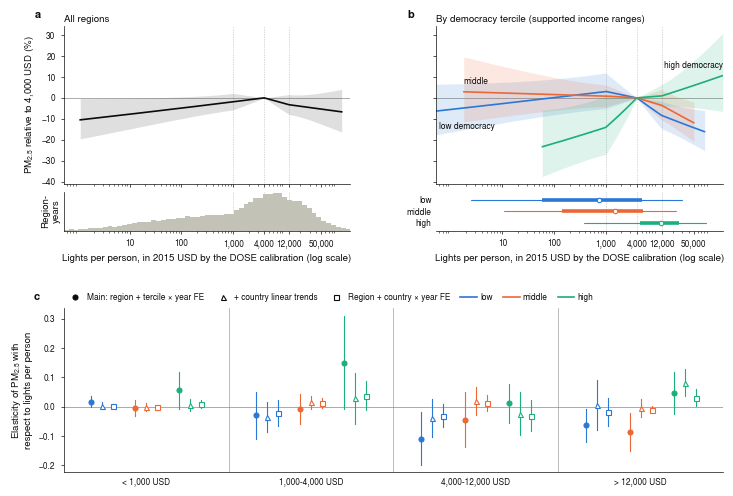

In [26]:
q = p.copy()
q['log_y'] = pl.usd_equivalent(q.log_lpc, k)
q = q.drop(columns=list(P.SEGMENTS)).join(P.spline_terms(q.log_y))
q['segment'] = P.segment(q.log_y)
print('segments unchanged:', (q.segment == p.segment).mean())
main_eq, pooled_eq = P.fit_paths(q, controls=()), P.fit_pooled(q, controls=())
fig = P.plot_paths(q, pooled_eq, {**main, 'model': main_eq['model']},
                   {'+ country trends': v1, 'country × year FE': v2})
for ax in (fig.axes[1], fig.axes[3]):
    ax.set_xlabel('Lights per person, in 2015 USD by the DOSE calibration (log scale)')
from matplotlib.ticker import FixedLocator
for ax in fig.axes[:4]:
    ax.xaxis.set_major_locator(FixedLocator([t for t in (10, 100, 1000, 4000, 12000, 50000)
                                             if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]]))
# panel b: put the middle tercile's label at its left end, clear of the low tercile's right end
ax_b = fig.axes[2]
mid = next(l for l in ax_b.lines if l.get_color() == P.GROUP_COLORS[1])
for t in [t for t in ax_b.texts if t.get_text() == 'middle']:
    t.remove()
ax_b.annotate('middle', (mid.get_xdata()[0], mid.get_ydata()[0]), xytext=(0, 4), textcoords='offset points',
              ha='left', va='bottom', fontsize=6, color=P.INK)
fig.axes[4].set_ylabel('Elasticity of PM$_{2.5}$ with\nrespect to lights per person')
fig = P._save(fig, f'{P.FIGURES}/pm25_lights_paths')

### Figure: variants 3–8

Segment elasticities with respect to lights per person, by democracy tercile (rule-of-law tercile for variant 3), with 95 % intervals (country clusters). **a**, Main specification and variants 3–5. **b**, Main specification and variants 6–8. Cells with fewer than 50 regions are left out. For variants 6 and 7 the DOSE calibration's within-year R² is below 0.5 (0.39 and 0.29), so by the §3 rule their knots are the quartiles of their own measure: their segments are quartiles, not the USD ranges on the axis. Variant 7's slopes are with respect to lights per area.

Saved to `output/figures/pollution/pm25_lights_variants.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


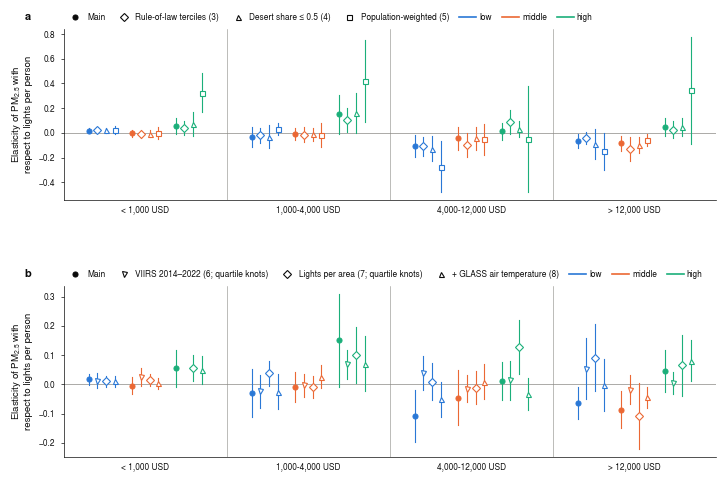

In [27]:
import matplotlib.pyplot as plt
P.nature_style()
fig, (a, b) = plt.subplots(2, 1, figsize=(183 / 25.4, 125 / 25.4),
                           gridspec_kw=dict(hspace=0.5, left=0.08, right=0.985, top=0.93, bottom=0.06))
P._slope_panel(a, {'Main': (main, 'o', True), 'Rule-of-law terciles (3)': (V['3 rule of law'], 'D', False),
                   'Desert share ≤ 0.5 (4)': (V['4 desert share <= 0.5'], '^', False),
                   'Population-weighted (5)': (V['5 pop-weighted PM2.5 + pop weights'], 's', False)}, [0, 1, 2])
P._slope_panel(b, {'Main': (main, 'o', True), 'VIIRS 2014–2022 (6; quartile knots)': (V['6 VIIRS years 2014-2022'], 'v', False),
                   'Lights per area (7; quartile knots)': (V['7 lights per area'], 'D', False),
                   '+ GLASS air temperature (8)': (V['8 + GLASS air temperature'], '^', False)}, [0, 1, 2])
for ax in (a, b):
    ax.set_ylabel('Elasticity of PM$_{2.5}$ with\nrespect to lights per person')
P._letters((a, b), (-0.06, -0.06))
fig = P._save(fig, f'{P.FIGURES}/pm25_lights_variants')